## Imports

In [113]:
import random
import cv2
from copy import deepcopy
from pathlib import Path
from typing import Sequence
from itertools import cycle

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytorch_lightning as pl
import torch
import torch.nn as nn
import torch.nn.functional as F
from albumentations.pytorch import ToTensorV2
from PIL import Image
from tqdm.auto import tqdm

from collections import Counter
from dataclasses import dataclass

## Constants

In [2]:
SEED = 1488
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 8
NUM_WORKERS = 0 

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print(f"DEVICE: {DEVICE}")

DEVICE: cuda


In [4]:
VOC_CLASSES = {
    0: "background",
    1: "aeroplane",
    2: "bicycle",
    3: "bird",
    4: "boat",
    5: "bottle",
    6: "bus",
    7: "car",
    8: "cat",
    9: "chair",
    10: "cow",
    11: "diningtable",
    12: "dog",
    13: "horse",
    14: "motorbike",
    15: "person",
    16: "pottedplant",
    17: "sheep",
    18: "sofa",
    19: "train",
    20: "tvmonitor",
    255: "ignore",
}

VOC_COLORMAP = np.array([
    [0, 0, 0],
    [128, 0, 0],
    [0, 128, 0],
    [128, 128, 0],
    [0, 0, 128],
    [128, 0, 128],
    [0, 128, 128],
    [128, 128, 128],
    [64, 0, 0],
    [192, 0, 0],
    [64, 128, 0],
    [192, 128, 0],
    [64, 0, 128],
    [192, 0, 128],
    [64, 128, 128],
    [192, 128, 128],
    [0, 64, 0],
    [128, 64, 0],
    [0, 192, 0],
    [128, 192, 0],
    [0, 64, 128],
], dtype=np.uint8)


In [5]:
def decode_target(mask: np.ndarray) -> np.ndarray:
    color_mask = np.zeros((*mask.shape, 3), dtype=np.uint8)
    valid = (mask >= 0) & (mask < len(VOC_COLORMAP))
    color_mask[valid] = VOC_COLORMAP[mask[valid]]
    color_mask[mask == 255] = np.array([255, 255, 255], dtype=np.uint8)
    return color_mask


def overlay_mask(image: np.ndarray, mask: np.ndarray, alpha: float = 0.45) -> np.ndarray:
    overlay = image.copy().astype(np.float32)
    color_mask = decode_target(mask)
    valid = (mask > 0) & (mask < 255)
    overlay[valid] = (1 - alpha) * overlay[valid] + alpha * color_mask[valid]
    overlay[mask == 255] = np.array([255, 255, 255], dtype=np.float32)
    return overlay.astype(np.uint8)

In [6]:
WORKSPACE_ROOT = Path("/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset")
VOC_ROOT = Path("/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val")
IMAGE_DIR = VOC_ROOT / "JPEGImages"
MASK_DIR = VOC_ROOT / "SegmentationClass"
TRAIN_SPLIT_PATH = VOC_ROOT / "ImageSets" / "Segmentation" / "train.txt"
VAL_SPLIT_PATH = VOC_ROOT / "ImageSets" / "Segmentation" / "val.txt"

print(f"WORKSPACE_ROOT: {WORKSPACE_ROOT}")
print(f"VOC_ROOT: {VOC_ROOT}")
print(f"TRAIN_SPLIT_PATH exists: {TRAIN_SPLIT_PATH.exists()}")
print(f"VAL_SPLIT_PATH exists: {VAL_SPLIT_PATH.exists()}")
print(f"IMAGE_DIR exists: {IMAGE_DIR.exists()}")
print(f"MASK_DIR exists: {MASK_DIR.exists()}")

WORKSPACE_ROOT: /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset
VOC_ROOT: /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val
TRAIN_SPLIT_PATH exists: True
VAL_SPLIT_PATH exists: True
IMAGE_DIR exists: True
MASK_DIR exists: True


## Data

In [50]:
train_ids = TRAIN_SPLIT_PATH.read_text().strip().splitlines()
val_ids = VAL_SPLIT_PATH.read_text().strip().splitlines()
train_set = set(train_ids)
val_set = set(val_ids)

In [51]:
split_df = pd.DataFrame({
    "image_id": train_ids + val_ids,
    "subset": ["train"] * len(train_ids) + ["val"] * len(val_ids),
})

split_df["image_path"] = split_df["image_id"].apply(lambda x: IMAGE_DIR / f"{x}.jpg")
split_df["mask_path"] = split_df["image_id"].apply(lambda x: MASK_DIR / f"{x}.png")

split_df.groupby("subset").size().to_frame("n_samples")

,n_samples
subset,
train,1464
val,1449


In [52]:
class VOCSegmentationDataset(torch.utils.data.Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        image = np.array(Image.open(row["image_path"]).convert("RGB"))
        mask = np.array(Image.open(row["mask_path"]))

        if self.transform is not None:
            transformed = self.transform(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        if torch.is_tensor(mask):
            mask = mask.long()

        return image, mask, row["image_id"]

    @classmethod
    def decode_target(cls, mask: np.ndarray) -> np.ndarray:
        return decode_target(mask)


In [53]:
class LitVOCDataModule(pl.LightningDataModule):
    def __init__(self, df: pd.DataFrame, batch_size: int = 8, num_workers: int = 4, train_tfms=None, val_tfms=None):
        super().__init__()
        self.df = df.copy()
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.train_tfms = train_tfms
        self.val_tfms = val_tfms

    def setup(self, stage=None):
        train_df = self.df[self.df["subset"] == "train"].reset_index(drop=True)
        val_df = self.df[self.df["subset"] == "val"].reset_index(drop=True)
        self.train_ds = VOCSegmentationDataset(train_df, transform=self.train_tfms)
        self.val_ds = VOCSegmentationDataset(val_df, transform=self.val_tfms)

    def train_dataloader(self):
        return torch.utils.data.DataLoader(
            self.train_ds,
            batch_size=self.batch_size,
            shuffle=True,
            num_workers=self.num_workers,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=self.num_workers > 0,
        )

    def val_dataloader(self):
        return torch.utils.data.DataLoader(
            self.val_ds,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=self.num_workers > 0,
        )

In [54]:
image_size = 256
train_tfms = A.Compose([
    A.Resize(image_size, image_size),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])
val_tfms = A.Compose([
    A.Resize(image_size, image_size),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

In [55]:
dm = LitVOCDataModule(split_df, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, train_tfms=train_tfms, val_tfms=val_tfms)
dm.setup()

In [56]:
train_batch = next(iter(dm.train_dataloader()))
images, masks, image_ids = train_batch
print(f"Batch image tensor shape: {tuple(images.shape)}")
print(f"Batch mask tensor shape: {tuple(masks.shape)}")

Batch image tensor shape: (8, 3, 256, 256)
Batch mask tensor shape: (8, 256, 256)


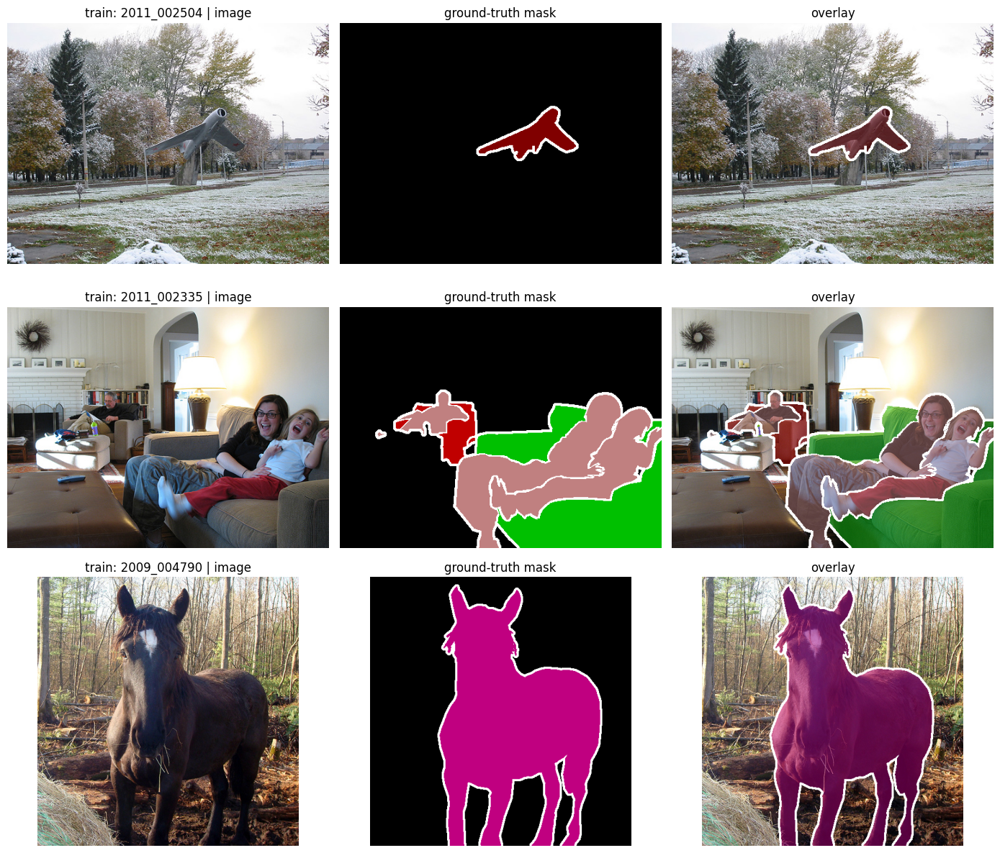

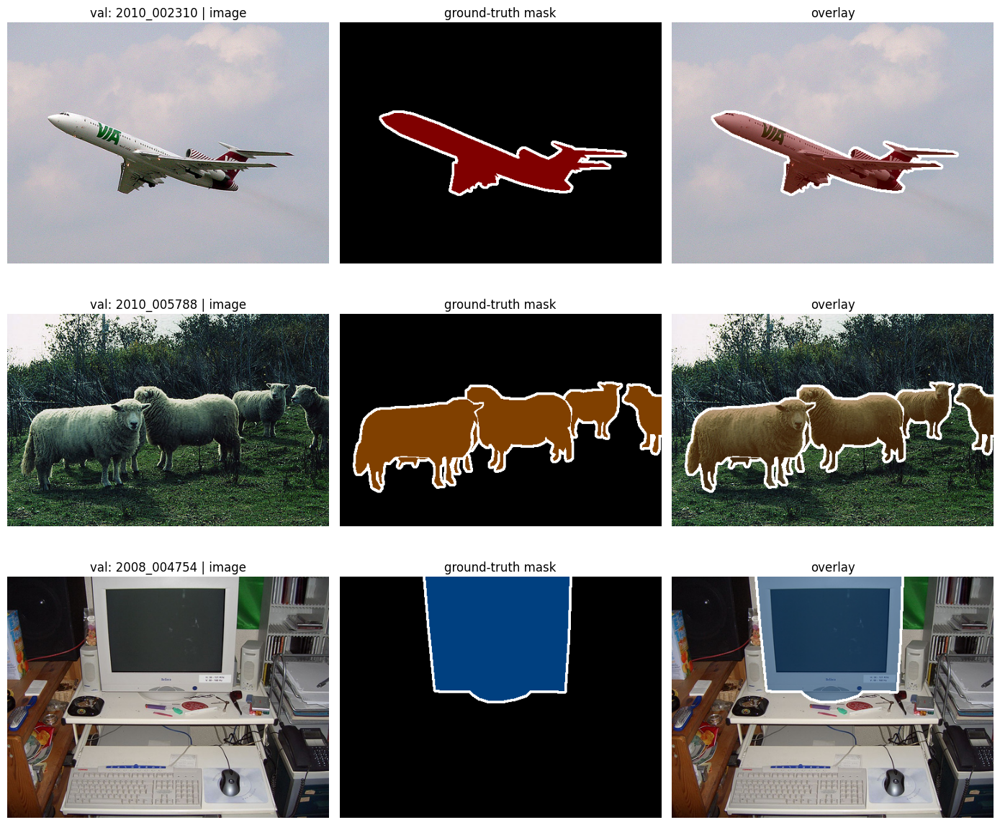

In [57]:
def show_random_samples(df: pd.DataFrame, subset: str, n_samples: int = 3) -> None:
    sampled_df = df[df["subset"] == subset].sample(min(n_samples, (df["subset"] == subset).sum()), random_state=SEED)
    fig, axes = plt.subplots(len(sampled_df), 3, figsize=(14, 4 * len(sampled_df)))
    if len(sampled_df) == 1:
        axes = np.expand_dims(axes, axis=0)

    for ax_row, (_, row) in zip(axes, sampled_df.iterrows()):
        image = np.array(Image.open(row["image_path"]).convert("RGB"))
        mask = np.array(Image.open(row["mask_path"]))
        overlay = overlay_mask(image, mask)

        ax_row[0].imshow(image)
        ax_row[0].set_title(f"{subset}: {row['image_id']} | image")
        ax_row[1].imshow(decode_target(mask))
        ax_row[1].set_title("ground-truth mask")
        ax_row[2].imshow(overlay)
        ax_row[2].set_title("overlay")

        for ax in ax_row:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_random_samples(split_df, subset="train", n_samples=3)
show_random_samples(split_df, subset="val", n_samples=3)

##  SSL Model Setup (DINOv2 + FPN)

In [59]:
MODEL_ARTIFACT_DIR = Path("../input/datasets/denysmykhailov/cv-task3-models")
OUTPUT_DIR = Path("/kaggle/working")
PSEUDO_OUTPUT_ROOT = OUTPUT_DIR / "generated"
PSEUDO_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

PSEUDO_TEACHER_CHECKPOINT = MODEL_ARTIFACT_DIR / "best_dinov2_fpn_partial_ft.pth"
INFERENCE_IMAGE_SIZE = 336
INFERENCE_BATCH_SIZE = BATCH_SIZE
INFERENCE_NUM_WORKERS = NUM_WORKERS

available_checkpoints = sorted(MODEL_ARTIFACT_DIR.glob("*.pth")) if MODEL_ARTIFACT_DIR.exists() else []

print(f"MODEL_ARTIFACT_DIR: {MODEL_ARTIFACT_DIR}")
print(f"Found checkpoints: {[path.name for path in available_checkpoints]}")
print(f"PSEUDO_OUTPUT_ROOT: {PSEUDO_OUTPUT_ROOT}")
print(f"PSEUDO_TEACHER_CHECKPOINT is empty: {PSEUDO_TEACHER_CHECKPOINT == ''}")
print(f"PSEUDO_TEACHER_CHECKPOINT: {PSEUDO_TEACHER_CHECKPOINT}")

MODEL_ARTIFACT_DIR: ../input/datasets/denysmykhailov/cv-task3-models
Found checkpoints: ['best_dinov2_fpn_frozen.pth', 'best_dinov2_fpn_partial_ft.pth']
PSEUDO_OUTPUT_ROOT: /kaggle/working/generated
PSEUDO_TEACHER_CHECKPOINT is empty: False
PSEUDO_TEACHER_CHECKPOINT: ../input/datasets/denysmykhailov/cv-task3-models/best_dinov2_fpn_partial_ft.pth


In [60]:
SSL_IMAGE_SIZE = 336 
NUM_CLASSES = 21
IGNORE_INDEX = 255
DINO_REPO_OR_DIR = "facebookresearch/dinov2"
DINO_BACKBONE_NAME = "dinov2_vits14"
DINO_PATCH_SIZE = 14
DINO_OUT_INDICES = (2, 5, 8, 11)
PYRAMID_CHANNELS = 192
SEGMENTATION_CHANNELS = 128
CHECKPOINT_DIR = Path("/kaggle/working")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

In [61]:
class ConvBNReLU(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)

In [62]:
class FPNSegmentationHead(nn.Module):
    def __init__(
        self,
        num_levels: int,
        pyramid_channels: int = 256,
        segmentation_channels: int = 128,
        num_classes: int = 21,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.blocks = nn.ModuleList([
            ConvBNReLU(pyramid_channels, segmentation_channels, kernel_size=3)
            for _ in range(num_levels)
        ])
        self.fuse = nn.Sequential(
            ConvBNReLU(num_levels * segmentation_channels, segmentation_channels, kernel_size=3),
            nn.Dropout2d(dropout) if dropout > 0 else nn.Identity(),
            nn.Conv2d(segmentation_channels, num_classes, kernel_size=1),
        )

    def forward(self, pyramid_features: list[torch.Tensor]) -> torch.Tensor:
        target_size = pyramid_features[0].shape[-2:]
        fused_features = []

        for feature, block in zip(pyramid_features, self.blocks):
            x = block(feature)
            if x.shape[-2:] != target_size:
                x = F.interpolate(x, size=target_size, mode="bilinear", align_corners=False)
            fused_features.append(x)

        return self.fuse(torch.cat(fused_features, dim=1))


In [63]:
class FPNDecoder(nn.Module):
    def __init__(self, encoder_channels: list[int], pyramid_channels: int = 256):
        super().__init__()
        self.lateral_convs = nn.ModuleList([
            nn.Conv2d(ch, pyramid_channels, kernel_size=1)
            for ch in encoder_channels
        ])
        self.output_convs = nn.ModuleList([
            nn.Conv2d(pyramid_channels, pyramid_channels, kernel_size=3, padding=1)
            for _ in encoder_channels
        ])

    def forward(self, features: list[torch.Tensor]) -> list[torch.Tensor]:
        laterals = [lat_conv(feature) for lat_conv, feature in zip(self.lateral_convs, features)]
        pyramid = [None] * len(laterals)
        pyramid[-1] = laterals[-1]

        for idx in range(len(laterals) - 2, -1, -1):
            upsampled = F.interpolate(
                pyramid[idx + 1],
                size=laterals[idx].shape[-2:],
                mode="nearest",
            )
            pyramid[idx] = laterals[idx] + upsampled

        return [conv(feature) for conv, feature in zip(self.output_convs, pyramid)]

In [64]:
class DINOv2FpnSegmentationModel(nn.Module):
    def __init__(
        self,
        repo_or_dir: str,
        backbone_name: str,
        num_classes: int,
        patch_size: int = 14,
        out_indices: Sequence[int] = (2, 5, 8, 11),
        pyramid_channels: int = 192,
        segmentation_channels: int = 128,
        freeze_backbone: bool = True,
        trainable_blocks: int = 0,
    ):
        super().__init__()
        self.repo_or_dir = repo_or_dir
        self.backbone_name = backbone_name
        self.patch_size = patch_size
        self.out_indices = tuple(out_indices)
        self.backbone = torch.hub.load(repo_or_dir=self.repo_or_dir, model=self.backbone_name)
        self.embed_dim = self._infer_embed_dim()

        self.decoder = FPNDecoder(
            encoder_channels=[self.embed_dim] * len(self.out_indices),
            pyramid_channels=pyramid_channels,
        )
        self.segmentation_head = FPNSegmentationHead(
            num_levels=len(self.out_indices),
            pyramid_channels=pyramid_channels,
            segmentation_channels=segmentation_channels,
            num_classes=num_classes,
        )
        self.set_backbone_trainability(freeze_backbone=freeze_backbone, trainable_blocks=trainable_blocks)

    def _infer_embed_dim(self) -> int:
        for attr in ["embed_dim", "num_features"]:
            if hasattr(self.backbone, attr):
                return int(getattr(self.backbone, attr))
        if hasattr(self.backbone, "blocks") and len(self.backbone.blocks) > 0:
            normalized_shape = self.backbone.blocks[0].norm1.normalized_shape
            return int(normalized_shape[0] if isinstance(normalized_shape, (tuple, list)) else normalized_shape)
        raise RuntimeError("Could not infer DINOv2 embedding dimension.")

    def set_backbone_trainability(self, freeze_backbone: bool = True, trainable_blocks: int = 0) -> None:
        for param in self.backbone.parameters():
            param.requires_grad = not freeze_backbone

        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

        if trainable_blocks > 0 and hasattr(self.backbone, "blocks"):
            for block in self.backbone.blocks[-trainable_blocks:]:
                for param in block.parameters():
                    param.requires_grad = True
            if hasattr(self.backbone, "norm"):
                for param in self.backbone.norm.parameters():
                    param.requires_grad = True

    def _tokens_to_map(self, tokens: torch.Tensor, input_size: tuple[int, int]) -> torch.Tensor:
        input_h, input_w = input_size
        grid_h = input_h // self.patch_size
        grid_w = input_w // self.patch_size
        batch_size, num_tokens, channels = tokens.shape
        expected_tokens = grid_h * grid_w
        if num_tokens != expected_tokens:
            raise RuntimeError(
                f"Token count mismatch: got {num_tokens}, expected {expected_tokens} for input {input_size}."
            )
        return tokens.transpose(1, 2).reshape(batch_size, channels, grid_h, grid_w)

    def _extract_token_features(self, x: torch.Tensor) -> list[torch.Tensor]:
        features = self.backbone.get_intermediate_layers(
            x,
            n=self.out_indices,
            reshape=False,
            return_class_token=False,
        )
        if isinstance(features, torch.Tensor):
            features = [features]
        token_features = []
        for feature in features:
            if isinstance(feature, (tuple, list)):
                feature = feature[0]
            token_features.append(feature)
        return token_features

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        input_size = x.shape[-2:]
        if input_size[0] % self.patch_size != 0 or input_size[1] % self.patch_size != 0:
            raise ValueError(f"Input size must be divisible by patch_size={self.patch_size}, got {input_size}.")

        if any(param.requires_grad for param in self.backbone.parameters()):
            token_features = self._extract_token_features(x)
        else:
            with torch.no_grad():
                token_features = self._extract_token_features(x)

        feature_maps = [self._tokens_to_map(tokens, input_size) for tokens in token_features]
        pyramid = self.decoder(feature_maps)
        logits = self.segmentation_head(pyramid)
        logits = F.interpolate(logits, size=input_size, mode="bilinear", align_corners=False)
        return logits


In [74]:
ssl_val_tfms = A.Compose([
    A.Resize(SSL_IMAGE_SIZE, SSL_IMAGE_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

In [81]:
@torch.no_grad()
def validate_checkpoint_on_full_val_set(checkpoint_path: str | Path) -> dict[str, object]:
    checkpoint_path = Path(str(checkpoint_path))
    if not str(checkpoint_path).strip():
        raise ValueError('Set PSEUDO_TEACHER_CHECKPOINT before running validation.')
    if not checkpoint_path.exists():
        raise FileNotFoundError(f'Checkpoint not found: {checkpoint_path}')

    val_df = split_df[split_df['subset'] == 'val'].reset_index(drop=True)
    val_ds = VOCSegmentationDataset(val_df, transform=ssl_val_tfms)
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=INFERENCE_BATCH_SIZE,
        shuffle=False,
        num_workers=INFERENCE_NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=INFERENCE_NUM_WORKERS > 0,
    )

    model = DINOv2FpnSegmentationModel(
        repo_or_dir=DINO_REPO_OR_DIR,
        backbone_name=DINO_BACKBONE_NAME,
        num_classes=NUM_CLASSES,
        patch_size=DINO_PATCH_SIZE,
        out_indices=DINO_OUT_INDICES,
        pyramid_channels=PYRAMID_CHANNELS,
        segmentation_channels=SEGMENTATION_CHANNELS,
        freeze_backbone=True,
        trainable_blocks=0,
    ).to(DEVICE)

    payload = torch.load(checkpoint_path, map_location=DEVICE)
    state_dict = payload['model_state_dict'] if isinstance(payload, dict) and 'model_state_dict' in payload else payload
    model.load_state_dict(state_dict)
    model.eval()

    criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    total_loss = 0.0
    total_batches = 0
    first_logits_shape = None

    for images, masks, _ in tqdm(val_loader, desc='checkpoint validation', leave=False):
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)
        logits = model(images)
        loss = criterion(logits, masks)
        if first_logits_shape is None:
            first_logits_shape = tuple(logits.shape)
        total_loss += float(loss.item())
        total_batches += 1

    summary = {
        'checkpoint_path': str(checkpoint_path),
        'val_batches': total_batches,
        'mean_val_loss': total_loss / max(total_batches, 1),
        'first_logits_shape': first_logits_shape,
    }
    print(pd.Series(summary))
    return summary


checkpoint_validation_summary = validate_checkpoint_on_full_val_set(PSEUDO_TEACHER_CHECKPOINT)

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


checkpoint validation:   0%|          | 0/182 [00:00<?, ?it/s]

checkpoint_path       ../input/datasets/denysmykhailov/cv-task3-mode...
val_batches                                                         182
mean_val_loss                                                  0.124581
first_logits_shape                                    (8, 21, 336, 336)
dtype: object


## Pseudo-Label Generation (Teacher -> Unlabeled Data)
This section generates confidence-filtered pseudo-labels from a trained DINOv2 + FPN teacher.

Important: set `PSEUDO_TEACHER_CHECKPOINT` to your `.pth` file path before running the teacher-loading cell.

In [90]:
@dataclass
class PseudoLabelConfig:
    threshold: float = 0.80
    ignore_index: int = 255
    batch_size: int = 8
    num_workers: int = 0
    min_component_area: int = 32
    max_images: int | None = None


def detect_voc_roots() -> tuple[Path, Path, Path]:
    candidates = [
        Path('/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val'),
        Path('ass3/VOC2012_train_val/VOC2012_train_val'),
        Path('ass3/VOC2012_train_val'),
        Path('VOC2012_train_val/VOC2012_train_val'),
        Path('VOC2012_train_val'),
    ]
    for root in candidates:
        image_dir = root / 'JPEGImages'
        mask_dir = root / 'SegmentationClass'
        train_txt = root / 'ImageSets' / 'Segmentation' / 'train.txt'
        val_txt = root / 'ImageSets' / 'Segmentation' / 'val.txt'
        if image_dir.exists() and mask_dir.exists() and train_txt.exists() and val_txt.exists():
            return root, image_dir, mask_dir
    raise FileNotFoundError('Could not detect VOC2012_train_val root. Update detect_voc_roots candidates.')


VOC_ROOT_AUTO, IMAGE_DIR_AUTO, MASK_DIR_AUTO = detect_voc_roots()
TEST_IMAGE_DIR_AUTO = Path('ass3/VOC2012_test/JPEGImages')
if not TEST_IMAGE_DIR_AUTO.exists():
    TEST_IMAGE_DIR_AUTO = Path('/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/JPEGImages')

PSEUDO_TEACHER_CHECKPOINT = str(PSEUDO_TEACHER_CHECKPOINT)
PSEUDO_OUTPUT_ROOT = Path(PSEUDO_OUTPUT_ROOT)
PSEUDO_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f'VOC_ROOT_AUTO: {VOC_ROOT_AUTO}')
print(f'IMAGE_DIR_AUTO: {IMAGE_DIR_AUTO}')
print(f'MASK_DIR_AUTO: {MASK_DIR_AUTO}')
print(f'TEST_IMAGE_DIR_AUTO exists: {TEST_IMAGE_DIR_AUTO.exists()}')
print(f'PSEUDO_OUTPUT_ROOT: {PSEUDO_OUTPUT_ROOT}')

VOC_ROOT_AUTO: /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val
IMAGE_DIR_AUTO: /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val/JPEGImages
MASK_DIR_AUTO: /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val/SegmentationClass
TEST_IMAGE_DIR_AUTO exists: True
PSEUDO_OUTPUT_ROOT: ass3/generated


In [76]:
def read_split_ids(voc_root: Path) -> tuple[set[str], set[str]]:
    train_ids_local = set((voc_root / 'ImageSets' / 'Segmentation' / 'train.txt').read_text().splitlines())
    val_ids_local = set((voc_root / 'ImageSets' / 'Segmentation' / 'val.txt').read_text().splitlines())
    return train_ids_local, val_ids_local


def build_unlabeled_dataframe(
    image_dir: Path,
    train_ids_local: set[str],
    val_ids_local: set[str],
    test_image_dir: Path | None = None,
    include_test_images: bool = False,
    max_images: int | None = None,
    seed: int = 1488,
    sort_ids: bool = True,
    ) -> pd.DataFrame:
    labeled_ids = train_ids_local | val_ids_local
    trainval_ids = {p.stem for p in image_dir.glob('*.jpg')}
    unlabeled_trainval_ids = list(trainval_ids - labeled_ids)
    if sort_ids:
        unlabeled_trainval_ids = sorted(unlabeled_trainval_ids)

    rows = [
        {
            'image_id': image_id,
            'image_path': image_dir / f'{image_id}.jpg',
            'source': 'trainval_unlabeled',
        }
        for image_id in unlabeled_trainval_ids
    ]

    if include_test_images and test_image_dir is not None and test_image_dir.exists():
        test_ids = sorted(p.stem for p in test_image_dir.glob('*.jpg'))
        rows.extend(
            {
                'image_id': image_id,
                'image_path': test_image_dir / f'{image_id}.jpg',
                'source': 'test_unlabeled',
            }
            for image_id in test_ids
        )

    unlabeled_df = pd.DataFrame(rows).drop_duplicates(subset=['image_id']).reset_index(drop=True)
    if max_images is not None and len(unlabeled_df) > max_images:
        unlabeled_df = unlabeled_df.sample(max_images, random_state=seed).reset_index(drop=True)

    return unlabeled_df


train_ids_local, val_ids_local = read_split_ids(VOC_ROOT_AUTO)
unlabeled_df = build_unlabeled_dataframe(
    image_dir=IMAGE_DIR_AUTO,
    train_ids_local=train_ids_local,
    val_ids_local=val_ids_local,
    test_image_dir=TEST_IMAGE_DIR_AUTO,
    include_test_images=False,
    max_images=None,
    seed=SEED,
    sort_ids=True,
    )

dataset_summary_rows = [
    {'split': 'labeled_train', 'count': len(train_ids_local)},
    {'split': 'labeled_val', 'count': len(val_ids_local)},
    {'split': 'labeled_total', 'count': len(train_ids_local | val_ids_local)},
    {'split': 'unlabeled_trainval_candidates', 'count': int((unlabeled_df['source'] == 'trainval_unlabeled').sum())},
    {'split': 'test_images_available', 'count': len(list(TEST_IMAGE_DIR_AUTO.glob('*.jpg'))) if TEST_IMAGE_DIR_AUTO.exists() else 0},
]

dataset_summary_df = pd.DataFrame(dataset_summary_rows)
display(dataset_summary_df)
display(unlabeled_df.head())

,split,count
0,labeled_train,1464
1,labeled_val,1449
2,labeled_total,2913
3,unlabeled_trainval_candidates,14212
4,test_images_available,16135


,image_id,image_path,source
0,2007_000027,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,trainval_unlabeled
1,2007_000272,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,trainval_unlabeled
2,2007_000423,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,trainval_unlabeled
3,2007_000664,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,trainval_unlabeled
4,2007_000807,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,trainval_unlabeled


In [92]:
class VOCUnlabeledImageDataset(torch.utils.data.Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        image = np.array(Image.open(row['image_path']).convert('RGB'))
        height, width = image.shape[:2]
        transformed = self.transform(image=image)
        image_tensor = transformed['image']
        return image_tensor, row['image_id'], int(height), int(width)


def remove_small_components_from_mask(mask: np.ndarray, min_area: int, ignore_index: int) -> np.ndarray:
    if min_area <= 0:
        return mask
    try:
        import cv2
    except ImportError:
        return mask

    cleaned = mask.copy()
    class_ids = np.unique(mask)
    class_ids = class_ids[(class_ids != 0) & (class_ids != ignore_index)]
    for class_id in class_ids:
        binary = (cleaned == class_id).astype(np.uint8)
        n_components, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
        for component_idx in range(1, n_components):
            area = stats[component_idx, cv2.CC_STAT_AREA]
            if area < min_area:
                cleaned[labels == component_idx] = ignore_index
    return cleaned


@torch.no_grad()
def generate_pseudo_labels(
    teacher_model: nn.Module,
    unlabeled_data: pd.DataFrame,
    output_dir: Path,
    cfg: PseudoLabelConfig,
    transform,
    device: str,
    ) -> pd.DataFrame:
    output_dir.mkdir(parents=True, exist_ok=True)
    mask_dir = output_dir / 'masks'
    mask_dir.mkdir(parents=True, exist_ok=True)

    dataset = VOCUnlabeledImageDataset(unlabeled_data, transform=transform)
    dataloader = torch.utils.data.DataLoader(
        dataset,
        batch_size=cfg.batch_size,
        shuffle=False,
        num_workers=cfg.num_workers,
        pin_memory=torch.cuda.is_available(),
        )

    source_by_image_id = dict(zip(unlabeled_data['image_id'], unlabeled_data['source']))
    image_path_by_image_id = dict(zip(unlabeled_data['image_id'], unlabeled_data['image_path']))

    teacher_model.eval()
    metadata_rows = []
    pixel_counter = Counter()
    foreground_pixel_counter = Counter()
    valid_ratios = []
    foreground_valid_ratios = []

    for images, image_ids, heights, widths in tqdm(dataloader, desc=f'pseudo thr={cfg.threshold:.2f}', leave=False):
        images = images.to(device)
        logits = teacher_model(images)
        probs = torch.softmax(logits, dim=1)
        conf_map, pred_mask = probs.max(dim=1)

        for idx in range(images.shape[0]):
            image_id = image_ids[idx]
            h = int(heights[idx])
            w = int(widths[idx])

            pred_resized = F.interpolate(
                pred_mask[idx:idx + 1].unsqueeze(1).float(),
                size=(h, w),
                mode='nearest',
            ).squeeze().cpu().numpy().astype(np.uint8)

            conf_resized = F.interpolate(
                conf_map[idx:idx + 1].unsqueeze(1),
                size=(h, w),
                mode='bilinear',
                align_corners=False,
            ).squeeze().cpu().numpy()

            pseudo_mask = pred_resized.copy()
            pseudo_mask[conf_resized < cfg.threshold] = cfg.ignore_index
            pseudo_mask = remove_small_components_from_mask(
                pseudo_mask,
                min_area=cfg.min_component_area,
                ignore_index=cfg.ignore_index,
            )

            valid_mask = pseudo_mask != cfg.ignore_index
            foreground_valid_mask = (pseudo_mask != cfg.ignore_index) & (pseudo_mask != 0)

            valid_ratio = float(valid_mask.mean())
            foreground_valid_ratio = float(foreground_valid_mask.mean())
            valid_ratios.append(valid_ratio)
            foreground_valid_ratios.append(foreground_valid_ratio)

            valid_conf = conf_resized[valid_mask]
            mean_conf = float(valid_conf.mean()) if valid_conf.size > 0 else 0.0

            classes, counts = np.unique(pseudo_mask[valid_mask], return_counts=True) if valid_mask.any() else (np.array([], dtype=np.int64), np.array([], dtype=np.int64))
            for class_id, count in zip(classes.tolist(), counts.tolist()):
                pixel_counter[int(class_id)] += int(count)

            fg_classes, fg_counts = np.unique(pseudo_mask[foreground_valid_mask], return_counts=True) if foreground_valid_mask.any() else (np.array([], dtype=np.int64), np.array([], dtype=np.int64))
            for class_id, count in zip(fg_classes.tolist(), fg_counts.tolist()):
                foreground_pixel_counter[int(class_id)] += int(count)

            class_list = sorted(int(c) for c in classes.tolist())
            class_names = [VOC_CLASSES.get(c, f'class_{c}') for c in class_list]
            non_background_classes = [c for c in class_list if c != 0]
            non_background_class_count = len(non_background_classes)
            is_only_background = bool(valid_mask.any() and non_background_class_count == 0)

            pseudo_path = mask_dir / f'{image_id}.png'
            Image.fromarray(pseudo_mask, mode='L').save(pseudo_path)

            metadata_rows.append({
                'image_id': image_id,
                'image_path': str(image_path_by_image_id.get(image_id, '')),
                'pseudo_path': str(pseudo_path),
                'mean_confidence': mean_conf,
                'valid_pixel_ratio': valid_ratio,
                'foreground_valid_pixel_ratio': foreground_valid_ratio,
                'is_only_background': is_only_background,
                'non_background_class_count': non_background_class_count,
                'predicted_class_ids': '|'.join(str(c) for c in class_list),
                'predicted_classes': '|'.join(class_names),
                'source': str(source_by_image_id.get(image_id, 'unknown')),
            })

    metadata_df = pd.DataFrame(metadata_rows).sort_values('image_id').reset_index(drop=True)
    metadata_path = output_dir / 'pseudo_labels_metadata.csv'
    metadata_df.to_csv(metadata_path, index=False)

    total_valid_pixels = max(sum(pixel_counter.values()), 1)
    distribution_rows = [
        {
            'class_id': class_id,
            'class_name': VOC_CLASSES.get(class_id, f'class_{class_id}'),
            'pixel_count': count,
            'pixel_ratio': count / total_valid_pixels,
        }
        for class_id, count in sorted(pixel_counter.items(), key=lambda x: x[1], reverse=True)
    ]
    distribution_df = pd.DataFrame(distribution_rows)
    distribution_path = output_dir / 'pseudo_class_distribution.csv'
    distribution_df.to_csv(distribution_path, index=False)

    total_foreground_pixels = max(sum(foreground_pixel_counter.values()), 1)
    foreground_distribution_rows = [
        {
            'class_id': class_id,
            'class_name': VOC_CLASSES.get(class_id, f'class_{class_id}'),
            'foreground_pixel_count': count,
            'foreground_pixel_ratio': count / total_foreground_pixels,
        }
        for class_id, count in sorted(foreground_pixel_counter.items(), key=lambda x: x[1], reverse=True)
    ]
    foreground_distribution_df = pd.DataFrame(foreground_distribution_rows)
    foreground_distribution_path = output_dir / 'pseudo_foreground_class_distribution.csv'
    foreground_distribution_df.to_csv(foreground_distribution_path, index=False)

    only_background_pct = float(100.0 * metadata_df['is_only_background'].mean()) if len(metadata_df) else 0.0
    stats = {
        'n_images': len(metadata_df),
        'mean_valid_pixel_ratio': float(np.mean(valid_ratios)) if valid_ratios else 0.0,
        'median_valid_pixel_ratio': float(np.median(valid_ratios)) if valid_ratios else 0.0,
        'mean_foreground_valid_pixel_ratio': float(np.mean(foreground_valid_ratios)) if foreground_valid_ratios else 0.0,
        'median_foreground_valid_pixel_ratio': float(np.median(foreground_valid_ratios)) if foreground_valid_ratios else 0.0,
        'only_background_image_pct': only_background_pct,
        'mean_non_background_class_count': float(metadata_df['non_background_class_count'].mean()) if len(metadata_df) else 0.0,
        'threshold': cfg.threshold,
        'metadata_csv': str(metadata_path),
        'class_distribution_csv': str(distribution_path),
        'foreground_class_distribution_csv': str(foreground_distribution_path),
    }
    print(pd.Series(stats))
    return metadata_df

In [78]:
def build_teacher_model_for_pseudo_labels(checkpoint_path: str) -> DINOv2FpnSegmentationModel:
    if not checkpoint_path or not str(checkpoint_path).strip():
        raise ValueError('Set PSEUDO_TEACHER_CHECKPOINT to your trained .pth path before loading teacher model.')

    teacher_model = DINOv2FpnSegmentationModel(
        repo_or_dir=DINO_REPO_OR_DIR,
        backbone_name=DINO_BACKBONE_NAME,
        num_classes=NUM_CLASSES,
        patch_size=DINO_PATCH_SIZE,
        out_indices=DINO_OUT_INDICES,
        pyramid_channels=PYRAMID_CHANNELS,
        segmentation_channels=SEGMENTATION_CHANNELS,
        freeze_backbone=True,
        trainable_blocks=0,
    ).to(DEVICE)

    payload = torch.load(checkpoint_path, map_location=DEVICE)
    state_dict = payload['model_state_dict'] if isinstance(payload, dict) and 'model_state_dict' in payload else payload
    teacher_model.load_state_dict(state_dict)
    teacher_model.eval()
    return teacher_model


pseudo_teacher_model = None
if PSEUDO_TEACHER_CHECKPOINT.strip():
    pseudo_teacher_model = build_teacher_model_for_pseudo_labels(PSEUDO_TEACHER_CHECKPOINT)
    print('Teacher model loaded successfully.')
else:
    print('PSEUDO_TEACHER_CHECKPOINT is empty. Fill it, then rerun this cell to load teacher model.')

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Teacher model loaded successfully.


In [79]:
pseudo_cfg = PseudoLabelConfig(
    threshold=0.80,
    ignore_index=IGNORE_INDEX,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    min_component_area=32,
    max_images=None,
    )

unlabeled_subset_df = unlabeled_df.copy()
if pseudo_cfg.max_images is not None and len(unlabeled_subset_df) > pseudo_cfg.max_images:
    unlabeled_subset_df = unlabeled_subset_df.sample(pseudo_cfg.max_images, random_state=SEED).reset_index(drop=True)

pseudo_output_dir = PSEUDO_OUTPUT_ROOT / f'pseudo_labels_thr_{int(pseudo_cfg.threshold * 100):03d}'
print(f'Pseudo output dir: {pseudo_output_dir}')
print(f'Number of unlabeled images for this run: {len(unlabeled_subset_df)}')

if pseudo_teacher_model is None:
    print('Teacher model is not loaded yet. Fill PSEUDO_TEACHER_CHECKPOINT and run the loader cell first.')
else:
    pseudo_metadata_df = generate_pseudo_labels(
        teacher_model=pseudo_teacher_model,
        unlabeled_data=unlabeled_subset_df,
        output_dir=pseudo_output_dir,
        cfg=pseudo_cfg,
        transform=ssl_val_tfms,
        device=DEVICE,
    )
    display(pseudo_metadata_df.head())
    display(pseudo_metadata_df[['mean_confidence', 'valid_pixel_ratio']].describe())

Pseudo output dir: ass3/generated/pseudo_labels_thr_080
Number of unlabeled images for this run: 14212


pseudo thr=0.80:   0%|          | 0/1777 [00:00<?, ?it/s]

/tmp/ipykernel_55/40554947.py:115: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(pseudo_mask, mode='L').save(pseudo_path)


n_images                                                                14212
mean_valid_pixel_ratio                                               0.933465
median_valid_pixel_ratio                                             0.951589
threshold                                                                 0.8
metadata_csv                ass3/generated/pseudo_labels_thr_080/pseudo_la...
class_distribution_csv      ass3/generated/pseudo_labels_thr_080/pseudo_cl...
dtype: object


,image_id,pseudo_path,mean_confidence,valid_pixel_ratio,predicted_class_ids,predicted_classes,source
0,2007_000027,ass3/generated/pseudo_labels_thr_080/masks/200...,0.993744,0.982486,0|15,background|person,trainval_unlabeled
1,2007_000272,ass3/generated/pseudo_labels_thr_080/masks/200...,0.990421,0.961988,0|15,background|person,trainval_unlabeled
2,2007_000423,ass3/generated/pseudo_labels_thr_080/masks/200...,0.985921,0.938837,0|15,background|person,trainval_unlabeled
3,2007_000664,ass3/generated/pseudo_labels_thr_080/masks/200...,0.991719,0.977061,0|15,background|person,trainval_unlabeled
4,2007_000807,ass3/generated/pseudo_labels_thr_080/masks/200...,0.990664,0.972305,0|15,background|person,trainval_unlabeled


,mean_confidence,valid_pixel_ratio
count,14212.000000,14212.000000
mean,0.985796,0.933465
std,0.008814,0.061214
min,0.894478,0.180085
25%,0.982195,0.914822
50%,0.987997,0.951589
75%,0.991781,0.971243
max,0.997956,1.000000


## Pseudo-Label Visualizations
Show a few pseudo-labeled samples and basic quality statistics after generation.

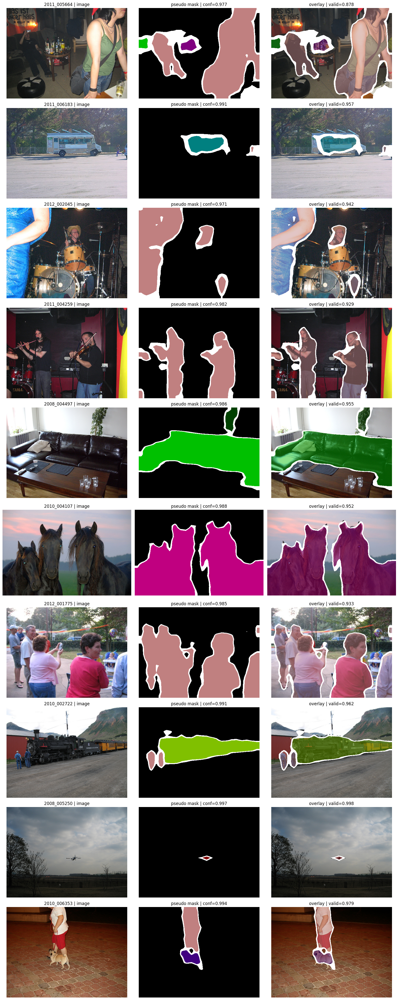

In [87]:
def load_pseudo_sample(row: pd.Series) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    image_path = row.get('image_path', None)
    if not image_path:
        if 'unlabeled_df' in globals():
            match = unlabeled_df.loc[unlabeled_df['image_id'] == row['image_id'], 'image_path']
            image_path = match.iloc[0] if not match.empty else None
    if not image_path:
        raise KeyError(f"Could not resolve image_path for pseudo sample {row['image_id']}.")

    image = np.array(Image.open(image_path).convert('RGB'))
    pseudo_mask = np.array(Image.open(row['pseudo_path']))
    overlay = overlay_mask(image, pseudo_mask)
    return image, pseudo_mask, overlay


def show_pseudo_label_gallery(metadata_df: pd.DataFrame, n_samples: int = 10) -> None:
    if metadata_df is None or metadata_df.empty:
        print('No pseudo-label metadata available to visualize.')
        return

    sample_df = metadata_df.sample(min(n_samples, len(metadata_df)), random_state=SEED).reset_index(drop=True)
    fig, axes = plt.subplots(len(sample_df), 3, figsize=(16, 4 * len(sample_df)))
    if len(sample_df) == 1:
        axes = np.expand_dims(axes, axis=0)

    for ax_row, (_, row) in zip(axes, sample_df.iterrows()):
        image, pseudo_mask, overlay = load_pseudo_sample(row)
        ax_row[0].imshow(image)
        ax_row[0].set_title(f"{row['image_id']} | image")
        ax_row[1].imshow(decode_target(pseudo_mask))
        ax_row[1].set_title(f"pseudo mask | conf={row['mean_confidence']:.3f}")
        ax_row[2].imshow(overlay)
        ax_row[2].set_title(f"overlay | valid={row['valid_pixel_ratio']:.3f}")
        for ax in ax_row:
            ax.axis('off')

    plt.tight_layout()
    plt.show()


if 'pseudo_metadata_df' in globals():
    show_pseudo_label_gallery(pseudo_metadata_df, n_samples=10)
else:
    print('pseudo_metadata_df is not available yet. Run the pseudo-label generation cell first.')

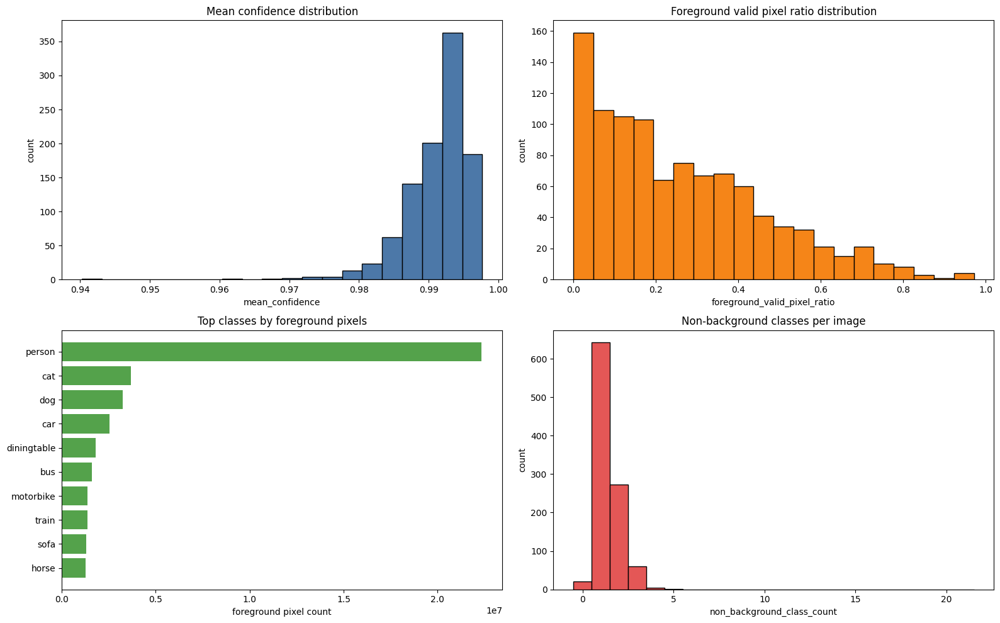

Only-background images: 2.00%


,mean_confidence,valid_pixel_ratio,foreground_valid_pixel_ratio,non_background_class_count
count,1000.0000,1000.0000,1000.0000,1000.0000
mean,0.9912,0.9002,0.2581,1.3910
std,0.0046,0.0796,0.2055,0.6637
min,0.9402,0.4079,0.0000,0.0000
25%,0.9891,0.8701,0.0859,1.0000
50%,0.9924,0.9247,0.2140,1.0000
75%,0.9943,0.9546,0.3875,2.0000
max,0.9977,1.0000,0.9711,5.0000


In [95]:
if 'pseudo_metadata_df' in globals() and not pseudo_metadata_df.empty:
    viz_df = pseudo_metadata_df.copy()

    if 'non_background_class_count' not in viz_df.columns:
        def _count_non_bg(class_ids_text: str) -> int:
            values = [token for token in str(class_ids_text).split('|') if token]
            class_ids = [int(token) for token in values] if values else []
            return sum(1 for class_id in class_ids if class_id != 0)

        viz_df['non_background_class_count'] = viz_df['predicted_class_ids'].map(_count_non_bg)

    if 'is_only_background' not in viz_df.columns:
        viz_df['is_only_background'] = viz_df['non_background_class_count'] == 0

    has_fg_ratio = 'foreground_valid_pixel_ratio' in viz_df.columns
    if not has_fg_ratio:
        print('foreground_valid_pixel_ratio is missing in current metadata. Re-run pseudo-label generation to get this metric.')

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    axes[0, 0].hist(viz_df['mean_confidence'], bins=20, color='#4C78A8', edgecolor='black')
    axes[0, 0].set_title('Mean confidence distribution')
    axes[0, 0].set_xlabel('mean_confidence')
    axes[0, 0].set_ylabel('count')

    if has_fg_ratio:
        axes[0, 1].hist(viz_df['foreground_valid_pixel_ratio'], bins=20, color='#F58518', edgecolor='black')
        axes[0, 1].set_title('Foreground valid pixel ratio distribution')
        axes[0, 1].set_xlabel('foreground_valid_pixel_ratio')
        axes[0, 1].set_ylabel('count')
    else:
        axes[0, 1].set_axis_off()
        axes[0, 1].text(0.5, 0.5, 'Missing foreground_valid_pixel_ratio\nRe-run pseudo-label generation', ha='center', va='center')

    if 'pseudo_output_dir' in globals():
        foreground_dist_path = pseudo_output_dir / 'pseudo_foreground_class_distribution.csv'
    else:
        foreground_dist_path = None

    if foreground_dist_path is not None and foreground_dist_path.exists():
        fg_dist_df = pd.read_csv(foreground_dist_path)
        top_fg = fg_dist_df.head(10).sort_values('foreground_pixel_count', ascending=True)
        axes[1, 0].barh(top_fg['class_name'], top_fg['foreground_pixel_count'], color='#54A24B')
        axes[1, 0].set_title('Top classes by foreground pixels')
        axes[1, 0].set_xlabel('foreground pixel count')
    else:
        axes[1, 0].set_axis_off()
        axes[1, 0].text(0.5, 0.5, 'Missing foreground pixel distribution CSV\nRe-run pseudo-label generation', ha='center', va='center')

    axes[1, 1].hist(viz_df['non_background_class_count'], bins=np.arange(-0.5, 22.5, 1), color='#E45756', edgecolor='black')
    axes[1, 1].set_title('Non-background classes per image')
    axes[1, 1].set_xlabel('non_background_class_count')
    axes[1, 1].set_ylabel('count')

    plt.tight_layout()
    plt.show()

    only_background_pct = 100.0 * float(viz_df['is_only_background'].mean())
    print(f'Only-background images: {only_background_pct:.2f}%')

    summary_cols = ['mean_confidence', 'valid_pixel_ratio', 'non_background_class_count']
    if has_fg_ratio:
        summary_cols.insert(2, 'foreground_valid_pixel_ratio')

    display(viz_df[summary_cols].describe().round(4))
else:
    print('pseudo_metadata_df is not available yet. Run the pseudo-label generation cell first.')

In [97]:
# Threshold sweep on a subset first (fast analysis stage).
threshold_grid = [0.70, 0.75, 0.80, 0.90]
max_images = 1000
pseudo_runs_summary = []

if pseudo_teacher_model is None:
    print('Teacher model is not loaded yet. Fill PSEUDO_TEACHER_CHECKPOINT and run the loader cell first.')
else:
    if len(unlabeled_df) > max_images:
        sweep_unlabeled_df = unlabeled_df.sample(max_images, random_state=SEED).reset_index(drop=True)
    else:
        sweep_unlabeled_df = unlabeled_df.copy()

    print(f'Sweep subset size: {len(sweep_unlabeled_df)}')

    for thr in threshold_grid:
        cfg = PseudoLabelConfig(
            threshold=thr,
            ignore_index=IGNORE_INDEX,
            batch_size=BATCH_SIZE,
            num_workers=NUM_WORKERS,
            min_component_area=32,
            max_images=max_images,
        )
        run_output_dir = PSEUDO_OUTPUT_ROOT / f'pseudo_labels_thr_{int(thr * 100):03d}_subset_{len(sweep_unlabeled_df)}'
        meta_df = generate_pseudo_labels(
            teacher_model=pseudo_teacher_model,
            unlabeled_data=sweep_unlabeled_df,
            output_dir=run_output_dir,
            cfg=cfg,
            transform=ssl_val_tfms,
            device=DEVICE,
        )
        pseudo_runs_summary.append({
            'threshold': thr,
            'n_images': len(meta_df),
            'mean_confidence': float(meta_df['mean_confidence'].mean()) if len(meta_df) else 0.0,
            'mean_valid_pixel_ratio': float(meta_df['valid_pixel_ratio'].mean()) if len(meta_df) else 0.0,
            'mean_foreground_valid_pixel_ratio': float(meta_df['foreground_valid_pixel_ratio'].mean()) if 'foreground_valid_pixel_ratio' in meta_df.columns and len(meta_df) else np.nan,
            'only_background_image_pct': float(100.0 * meta_df['is_only_background'].mean()) if 'is_only_background' in meta_df.columns and len(meta_df) else np.nan,
            'mean_non_background_class_count': float(meta_df['non_background_class_count'].mean()) if 'non_background_class_count' in meta_df.columns and len(meta_df) else np.nan,
            'metadata_csv': str(run_output_dir / 'pseudo_labels_metadata.csv'),
        })

if pseudo_runs_summary:
    pseudo_runs_summary_df = pd.DataFrame(pseudo_runs_summary)
    display(pseudo_runs_summary_df.round(4))

Sweep subset size: 1000


pseudo thr=0.70:   0%|          | 0/125 [00:00<?, ?it/s]

/tmp/ipykernel_55/788612245.py:129: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(pseudo_mask, mode='L').save(pseudo_path)


n_images                                                                            1000
mean_valid_pixel_ratio                                                          0.957724
median_valid_pixel_ratio                                                        0.970762
mean_foreground_valid_pixel_ratio                                               0.289094
median_foreground_valid_pixel_ratio                                             0.254339
only_background_image_pct                                                            0.9
mean_non_background_class_count                                                    1.487
threshold                                                                            0.7
metadata_csv                           ass3/generated/pseudo_labels_thr_070_subset_10...
class_distribution_csv                 ass3/generated/pseudo_labels_thr_070_subset_10...
foreground_class_distribution_csv      ass3/generated/pseudo_labels_thr_070_subset_10...
dtype: object


pseudo thr=0.75:   0%|          | 0/125 [00:00<?, ?it/s]

...

pseudo thr=0.80:   0%|          | 0/125 [00:00<?, ?it/s]

n_images                                                                            1000
mean_valid_pixel_ratio                                                          0.935316
median_valid_pixel_ratio                                                        0.952817
mean_foreground_valid_pixel_ratio                                               0.276982
median_foreground_valid_pixel_ratio                                             0.238782
only_background_image_pct                                                            1.2
mean_non_background_class_count                                                    1.444
threshold                                                                            0.8
metadata_csv                           ass3/generated/pseudo_labels_thr_080_subset_10...
class_distribution_csv                 ass3/generated/pseudo_labels_thr_080_subset_10...
foreground_class_distribution_csv      ass3/generated/pseudo_labels_thr_080_subset_10...
dtype: object


pseudo thr=0.90:   0%|          | 0/125 [00:00<?, ?it/s]

n_images                                                                            1000
mean_valid_pixel_ratio                                                          0.900155
median_valid_pixel_ratio                                                        0.924724
mean_foreground_valid_pixel_ratio                                               0.258136
median_foreground_valid_pixel_ratio                                             0.214019
only_background_image_pct                                                            2.0
mean_non_background_class_count                                                    1.391
threshold                                                                            0.9
metadata_csv                           ass3/generated/pseudo_labels_thr_090_subset_10...
class_distribution_csv                 ass3/generated/pseudo_labels_thr_090_subset_10...
foreground_class_distribution_csv      ass3/generated/pseudo_labels_thr_090_subset_10...
dtype: object


,threshold,n_images,mean_confidence,mean_valid_pixel_ratio,mean_foreground_valid_pixel_ratio,only_background_image_pct,mean_non_background_class_count,metadata_csv
0,0.70,1000,0.9805,0.9577,0.2891,0.9,1.487,ass3/generated/pseudo_labels_thr_070_subset_10...
1,0.75,1000,0.9833,0.9473,0.2834,0.9,1.464,ass3/generated/pseudo_labels_thr_075_subset_10...
2,0.80,1000,0.9860,0.9353,0.2770,1.2,1.444,ass3/generated/pseudo_labels_thr_080_subset_10...
3,0.90,1000,0.9912,0.9002,0.2581,2.0,1.391,ass3/generated/pseudo_labels_thr_090_subset_10...


## Same-Image Threshold Comparison
Visual comparison of pseudo-labels for the same images across all thresholds in `threshold_grid`.

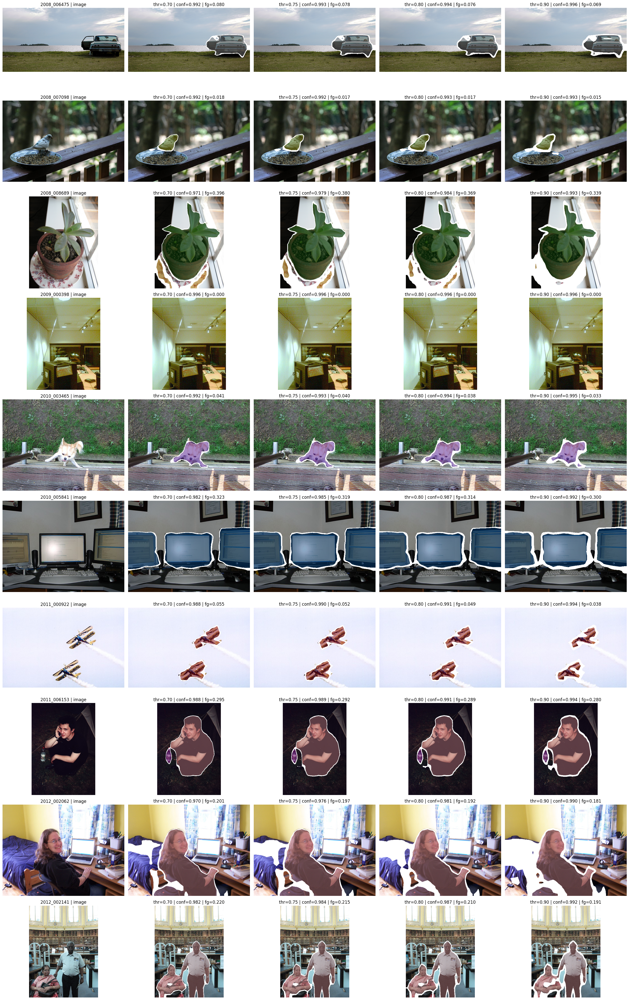

Compared image count: 10


In [98]:
def show_same_images_across_thresholds(
    runs_df: pd.DataFrame,
    thresholds: list[float],
    n_images: int = 10,
    seed: int = 1488,
 ) -> list[str]:
    if runs_df is None or runs_df.empty:
        print('pseudo_runs_summary_df is empty. Run threshold sweep first.')
        return []

    by_threshold_meta = {}
    for thr in thresholds:
        matched = runs_df.loc[runs_df['threshold'] == thr]
        if matched.empty:
            continue
        metadata_path = Path(matched.iloc[0]['metadata_csv'])
        if not metadata_path.exists():
            print(f'Metadata file not found for threshold {thr}: {metadata_path}')
            continue
        meta_df = pd.read_csv(metadata_path)
        by_threshold_meta[thr] = meta_df.set_index('image_id')

    available_thresholds = sorted(by_threshold_meta.keys())
    if not available_thresholds:
        print('No valid metadata files were found for threshold comparison.')
        return []

    common_ids = None
    for thr in available_thresholds:
        ids = set(by_threshold_meta[thr].index.tolist())
        common_ids = ids if common_ids is None else (common_ids & ids)

    common_ids = sorted(common_ids) if common_ids else []
    if not common_ids:
        print('No common image IDs found across thresholds.')
        return []

    rng = np.random.default_rng(seed)
    chosen_count = min(n_images, len(common_ids))
    selected_ids = sorted(rng.choice(common_ids, size=chosen_count, replace=False).tolist())

    n_cols = 1 + len(available_thresholds)
    fig, axes = plt.subplots(chosen_count, n_cols, figsize=(5 * n_cols, 4 * chosen_count))
    if chosen_count == 1:
        axes = np.expand_dims(axes, axis=0)

    for row_idx, image_id in enumerate(selected_ids):
        ref_row = by_threshold_meta[available_thresholds[0]].loc[image_id]
        image_path = ref_row.get('image_path', None)
        if (not image_path) and ('unlabeled_df' in globals()):
            match = unlabeled_df.loc[unlabeled_df['image_id'] == image_id, 'image_path']
            image_path = match.iloc[0] if not match.empty else None

        if not image_path:
            for ax in axes[row_idx]:
                ax.axis('off')
            continue

        image = np.array(Image.open(image_path).convert('RGB'))
        axes[row_idx, 0].imshow(image)
        axes[row_idx, 0].set_title(f'{image_id} | image')
        axes[row_idx, 0].axis('off')

        for col_idx, thr in enumerate(available_thresholds, start=1):
            row = by_threshold_meta[thr].loc[image_id]
            pseudo_path = row['pseudo_path']
            pseudo_mask = np.array(Image.open(pseudo_path))
            overlay = overlay_mask(image, pseudo_mask)
            fg_ratio = row['foreground_valid_pixel_ratio'] if 'foreground_valid_pixel_ratio' in row.index else np.nan
            axes[row_idx, col_idx].imshow(overlay)
            axes[row_idx, col_idx].set_title(
                f"thr={thr:.2f} | conf={row['mean_confidence']:.3f} | fg={fg_ratio:.3f}"
            )
            axes[row_idx, col_idx].axis('off')

    plt.tight_layout()
    plt.show()
    return selected_ids


if 'pseudo_runs_summary_df' in globals() and not pseudo_runs_summary_df.empty:
    compared_image_ids = show_same_images_across_thresholds(
        runs_df=pseudo_runs_summary_df,
        thresholds=threshold_grid,
        n_images=10,
        seed=SEED,
    )
    print(f'Compared image count: {len(compared_image_ids)}')
else:
    print('Run the threshold sweep cell first to generate pseudo_runs_summary_df.')

In [100]:
# Pick one sweep run for detailed visualization.
selected_threshold_for_viz = 0.75
selected_metadata_path = Path(
    pseudo_runs_summary_df.loc[pseudo_runs_summary_df['threshold'] == selected_threshold_for_viz, 'metadata_csv'].iloc[0]
 )
pseudo_output_dir = selected_metadata_path.parent
pseudo_metadata_df = pd.read_csv(selected_metadata_path)

print(f'Selected threshold: {selected_threshold_for_viz}')
print(f'pseudo_output_dir: {pseudo_output_dir}')
display(pseudo_metadata_df.head())

Selected threshold: 0.75
pseudo_output_dir: ass3/generated/pseudo_labels_thr_075_subset_1000


,image_id,image_path,pseudo_path,mean_confidence,valid_pixel_ratio,foreground_valid_pixel_ratio,is_only_background,non_background_class_count,predicted_class_ids,predicted_classes,source
0,2007_001667,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.995358,0.992703,0.014607,False,1,0|15,background|person,trainval_unlabeled
1,2007_002262,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.984319,0.970667,0.712709,False,1,0|15,background|person,trainval_unlabeled
2,2007_004133,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.979622,0.958425,0.121946,False,2,0|5|15,background|bottle|person,trainval_unlabeled
3,2007_006442,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.984712,0.951379,0.619276,False,2,0|9|15,background|chair|person,trainval_unlabeled
4,2007_006856,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.958799,0.851813,0.350816,False,2,0|9|15,background|chair|person,trainval_unlabeled


## Train Student Model on Pseudo-Labels

In [103]:
FIRST_ITERATION_MAX_IMAGES = 5000
FINAL_THRESHOLD = 0.75
REAL_LABEL_WEIGHT = 1.0
PSEUDO_LABEL_WEIGHT = 0.25
PSEUDO_IGNORE_BACKGROUND = True
STUDENT_EPOCHS = 12
STUDENT_LR = 1e-4
STUDENT_WEIGHT_DECAY = 1e-4

In [104]:
print('Generate pseudo labels at threshold=0.75 on 5k images')

full_pseudo_cfg = PseudoLabelConfig(
    threshold=FINAL_THRESHOLD,
    ignore_index=IGNORE_INDEX,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    min_component_area=32,
    max_images=FIRST_ITERATION_MAX_IMAGES,
)

full_unlabeled_df = unlabeled_df.copy()
if len(full_unlabeled_df) > FIRST_ITERATION_MAX_IMAGES:
    full_unlabeled_df = full_unlabeled_df.sample(FIRST_ITERATION_MAX_IMAGES, random_state=SEED).reset_index(drop=True)

full_pseudo_output_dir = PSEUDO_OUTPUT_ROOT / f'pseudo_labels_thr_{int(FINAL_THRESHOLD * 100):03d}_subset_{len(full_unlabeled_df)}'
print(f'Generating pseudo labels for {len(full_unlabeled_df)} unlabeled images...')

full_pseudo_metadata_df = generate_pseudo_labels(
    teacher_model=pseudo_teacher_model,
    unlabeled_data=full_unlabeled_df,
    output_dir=full_pseudo_output_dir,
    cfg=full_pseudo_cfg,
    transform=ssl_val_tfms,
    device=DEVICE,
)
print(f'Generated pseudo labels into: {full_pseudo_output_dir}')

Generate pseudo labels at threshold=0.75 on 5k images
Generating pseudo labels for 5000 unlabeled images...


pseudo thr=0.75:   0%|          | 0/625 [00:00<?, ?it/s]

/tmp/ipykernel_55/788612245.py:129: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(pseudo_mask, mode='L').save(pseudo_path)


n_images                                                                            5000
mean_valid_pixel_ratio                                                           0.94611
median_valid_pixel_ratio                                                        0.961805
mean_foreground_valid_pixel_ratio                                               0.269994
median_foreground_valid_pixel_ratio                                              0.22826
only_background_image_pct                                                            1.1
mean_non_background_class_count                                                   1.4834
threshold                                                                           0.75
metadata_csv                           ass3/generated/pseudo_labels_thr_075_subset_50...
class_distribution_csv                 ass3/generated/pseudo_labels_thr_075_subset_50...
foreground_class_distribution_csv      ass3/generated/pseudo_labels_thr_075_subset_50...
dtype: object
Generat

In [105]:
print('Train student with weighted real+pseudo loss')

class PseudoSegmentationDataset(torch.utils.data.Dataset):
    def __init__(self, metadata_df: pd.DataFrame, transform, ignore_index: int, ignore_background: bool):
        self.df = metadata_df.reset_index(drop=True).copy()
        self.transform = transform
        self.ignore_index = ignore_index
        self.ignore_background = ignore_background

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        image = np.array(Image.open(row['image_path']).convert('RGB'))
        mask = np.array(Image.open(row['pseudo_path'])).astype(np.uint8)
        if self.ignore_background:
            mask = mask.copy()
            mask[mask == 0] = self.ignore_index
        transformed = self.transform(image=image, mask=mask)
        image_tensor = transformed['image']
        mask_tensor = transformed['mask'].long() if torch.is_tensor(transformed['mask']) else torch.from_numpy(transformed['mask']).long()
        return image_tensor, mask_tensor, row['image_id']

@torch.no_grad()
def evaluate_segmentation_model(model, dataloader, device, ignore_index=255):
    model.eval()
    criterion = nn.CrossEntropyLoss(ignore_index=ignore_index)
    total_loss, total_batches, total_correct, total_valid = 0.0, 0, 0, 0
    intersection = torch.zeros(NUM_CLASSES, dtype=torch.float64)
    union = torch.zeros(NUM_CLASSES, dtype=torch.float64)

    for images, masks, _ in tqdm(dataloader, desc='val', leave=False):
        images, masks = images.to(device), masks.to(device)
        logits = model(images)
        loss = criterion(logits, masks)
        total_loss += float(loss.item())
        total_batches += 1

        preds = logits.argmax(dim=1)
        valid = masks != ignore_index
        total_correct += int((preds[valid] == masks[valid]).sum().item())
        total_valid += int(valid.sum().item())

        for class_id in range(NUM_CLASSES):
            pred_c = preds == class_id
            true_c = masks == class_id
            intersection[class_id] += (pred_c & true_c & valid).sum().item()
            union[class_id] += ((pred_c | true_c) & valid).sum().item()

    iou = intersection / torch.clamp(union, min=1.0)
    valid_classes = union > 0
    mean_iou = float(iou[valid_classes].mean().item()) if valid_classes.any() else 0.0
    return {
        'val_loss': total_loss / max(total_batches, 1),
        'val_pixel_accuracy': float(total_correct / max(total_valid, 1)),
        'val_mIoU': mean_iou,
    }

student_train_tfms = A.Compose([
    A.Resize(SSL_IMAGE_SIZE, SSL_IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

student_val_tfms = A.Compose([
    A.Resize(SSL_IMAGE_SIZE, SSL_IMAGE_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

labeled_train_df = split_df[split_df['subset'] == 'train'].reset_index(drop=True)
labeled_val_df = split_df[split_df['subset'] == 'val'].reset_index(drop=True)

real_loader = torch.utils.data.DataLoader(
    VOCSegmentationDataset(labeled_train_df, student_train_tfms),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)

pseudo_loader = torch.utils.data.DataLoader(
    PseudoSegmentationDataset(full_pseudo_metadata_df, student_train_tfms, IGNORE_INDEX, PSEUDO_IGNORE_BACKGROUND),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)

val_loader = torch.utils.data.DataLoader(
    VOCSegmentationDataset(labeled_val_df, student_val_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)

student_model = DINOv2FpnSegmentationModel(
    repo_or_dir=DINO_REPO_OR_DIR,
    backbone_name=DINO_BACKBONE_NAME,
    num_classes=NUM_CLASSES,
    patch_size=DINO_PATCH_SIZE,
    out_indices=DINO_OUT_INDICES,
    pyramid_channels=PYRAMID_CHANNELS,
    segmentation_channels=SEGMENTATION_CHANNELS,
    freeze_backbone=True,
    trainable_blocks=0,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.AdamW(
    [p for p in student_model.parameters() if p.requires_grad],
    lr=STUDENT_LR,
    weight_decay=STUDENT_WEIGHT_DECAY,
)

pseudo_iterator = cycle(pseudo_loader)
student_history_rows = []

Train student with weighted real+pseudo loss


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


In [106]:
print(f'Training student for {STUDENT_EPOCHS} epochs with real_weight={REAL_LABEL_WEIGHT}, pseudo_weight={PSEUDO_LABEL_WEIGHT}')
print(f'Real training samples: {len(labeled_train_df)}, Pseudo samples: {len(full_pseudo_metadata_df)}')

for epoch in range(1, STUDENT_EPOCHS + 1):
    student_model.train()
    running_real, running_pseudo, running_total, step_count = 0.0, 0.0, 0.0, 0

    for real_images, real_masks, _ in tqdm(real_loader, desc=f'train epoch {epoch}/{STUDENT_EPOCHS}', leave=False):
        pseudo_images, pseudo_masks, _ = next(pseudo_iterator)
        real_images, real_masks = real_images.to(DEVICE), real_masks.to(DEVICE)
        pseudo_images, pseudo_masks = pseudo_images.to(DEVICE), pseudo_masks.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        loss_real = criterion(student_model(real_images), real_masks)
        loss_pseudo = criterion(student_model(pseudo_images), pseudo_masks)
        total_loss = REAL_LABEL_WEIGHT * loss_real + PSEUDO_LABEL_WEIGHT * loss_pseudo
        total_loss.backward()
        optimizer.step()

        running_real += float(loss_real.item())
        running_pseudo += float(loss_pseudo.item())
        running_total += float(total_loss.item())
        step_count += 1

    val_metrics = evaluate_segmentation_model(student_model, val_loader, DEVICE, IGNORE_INDEX)
    row = {
        'epoch': epoch,
        'train_real_loss': running_real / max(step_count, 1),
        'train_pseudo_loss': running_pseudo / max(step_count, 1),
        'train_weighted_total_loss': running_total / max(step_count, 1),
        **val_metrics,
    }
    student_history_rows.append(row)
    print(pd.Series(row).round(4))

student_history_df = pd.DataFrame(student_history_rows)
student_eval_metrics = student_history_df.iloc[-1][['val_loss', 'val_pixel_accuracy', 'val_mIoU']].to_dict()
student_checkpoint_path = CHECKPOINT_DIR / 'student_frozen_dino_thr75_rw1.00_pw0.25_subset5k.pth'
torch.save({
    'model_state_dict': student_model.state_dict(),
    'config': {
        'threshold': FINAL_THRESHOLD,
        'real_weight': REAL_LABEL_WEIGHT,
        'pseudo_weight': PSEUDO_LABEL_WEIGHT,
        'epochs': STUDENT_EPOCHS,
        'max_images': FIRST_ITERATION_MAX_IMAGES,
    },
    'history': student_history_rows,
}, student_checkpoint_path)
print(f'\nStudent checkpoint saved: {student_checkpoint_path}')

Training student for 12 epochs with real_weight=1.0, pseudo_weight=0.25
Real training samples: 1464, Pseudo samples: 5000


train epoch 1/12:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

epoch                        1.0000
train_real_loss              1.5261
train_pseudo_loss            1.0151
train_weighted_total_loss    1.7799
val_loss                     0.9437
val_pixel_accuracy           0.9024
val_mIoU                     0.6577
dtype: float64


train epoch 2/12:   0%|          | 0/183 [00:00<?, ?it/s]

...

val:   0%|          | 0/182 [00:00<?, ?it/s]

epoch                        11.0000
train_real_loss               0.1243
train_pseudo_loss             0.1288
train_weighted_total_loss     0.1565
val_loss                      0.1536
val_pixel_accuracy            0.9519
val_mIoU                      0.7720
dtype: float64


train epoch 12/12:   0%|          | 0/183 [00:00<?, ?it/s]

val:   0%|          | 0/182 [00:00<?, ?it/s]

epoch                        12.0000
train_real_loss               0.1162
train_pseudo_loss             0.1162
train_weighted_total_loss     0.1452
val_loss                      0.1479
val_pixel_accuracy            0.9523
val_mIoU                      0.7959
dtype: float64

Student checkpoint saved: /kaggle/working/student_frozen_dino_thr75_rw1.00_pw0.25_subset5k.pth


In [107]:
print('Evaluate student on full validation set')

val_df_final = split_df[split_df['subset'] == 'val'].reset_index(drop=True)
final_val_loader = torch.utils.data.DataLoader(
    VOCSegmentationDataset(val_df_final, student_val_tfms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=NUM_WORKERS > 0,
)

final_metrics = evaluate_segmentation_model(student_model, final_val_loader, DEVICE, IGNORE_INDEX)
print('\nFinal validation metrics:')
print(pd.Series(final_metrics).round(4))

Evaluate student on full validation set


val:   0%|          | 0/182 [00:00<?, ?it/s]


Final validation metrics:
val_loss              0.1479
val_pixel_accuracy    0.9523
val_mIoU              0.7959
dtype: float64


| metric             | frozen   | partial_finetune | delta_partial_minus_frozen | semi_supervised |
| ------------------ | -------- | ---------------- | -------------------------- | --------------- |
| val_mIoU           | 0.833559 | 0.832688         | -0.000872                  | 0.8177          |
| val_Dice           | 0.903937 | 0.904081         | 0.000144                   | —               |
| val_loss           | 0.109894 | 0.127165         | 0.017272                   | 0.1349          |
| val_pixel_accuracy | —        | —                | —                          | 0.9523          |


## Interactive

In [114]:
INTERACTIVE_OUTPUT_DIR = Path("ass3/generated/interactive_labels")
INTERACTIVE_MASK_DIR = INTERACTIVE_OUTPUT_DIR / "masks"
INTERACTIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
INTERACTIVE_MASK_DIR.mkdir(parents=True, exist_ok=True)

print(f"INTERACTIVE_OUTPUT_DIR: {INTERACTIVE_OUTPUT_DIR}")
print(f"INTERACTIVE_MASK_DIR: {INTERACTIVE_MASK_DIR}")

INTERACTIVE_OUTPUT_DIR: ass3/generated/interactive_labels
INTERACTIVE_MASK_DIR: ass3/generated/interactive_labels/masks


In [115]:
def _load_interactive_source_df() -> pd.DataFrame:
    if "pseudo_metadata_df" in globals() and isinstance(pseudo_metadata_df, pd.DataFrame) and not pseudo_metadata_df.empty:
        return pseudo_metadata_df.copy()

    if "full_pseudo_metadata_df" in globals() and isinstance(full_pseudo_metadata_df, pd.DataFrame) and not full_pseudo_metadata_df.empty:
        return full_pseudo_metadata_df.copy()

    if "pseudo_runs_summary_df" in globals() and isinstance(pseudo_runs_summary_df, pd.DataFrame) and not pseudo_runs_summary_df.empty:
        runs_df = pseudo_runs_summary_df.copy()
        if 0.90 in set(runs_df["threshold"].tolist()):
            metadata_path = Path(runs_df.loc[runs_df["threshold"] == 0.90, "metadata_csv"].iloc[0])
        else:
            metadata_path = Path(runs_df.sort_values("threshold", ascending=False).iloc[0]["metadata_csv"])
        if metadata_path.exists():
            return pd.read_csv(metadata_path)

    raise ValueError("No pseudo-label metadata table is available. Run the pseudo-label generation section first.")


interactive_source_df = _load_interactive_source_df()

if "foreground_valid_pixel_ratio" not in interactive_source_df.columns:
    if "valid_pixel_ratio" in interactive_source_df.columns:
        interactive_source_df["foreground_valid_pixel_ratio"] = interactive_source_df["valid_pixel_ratio"]
    else:
        interactive_source_df["foreground_valid_pixel_ratio"] = np.nan

if "predicted_classes" not in interactive_source_df.columns:
    interactive_source_df["predicted_classes"] = ""

interactive_candidates_df = (
    interactive_source_df[
        (interactive_source_df["foreground_valid_pixel_ratio"] > 0.01)
        & (interactive_source_df["foreground_valid_pixel_ratio"] < 0.70)
    ]
    .sort_values(["mean_confidence", "foreground_valid_pixel_ratio"], ascending=[True, False])
    .loc[:, [
        "image_id",
        "image_path",
        "pseudo_path",
        "mean_confidence",
        "foreground_valid_pixel_ratio",
        "predicted_classes",
    ]]
    .reset_index(drop=True)
    .copy()
)

display(interactive_candidates_df.head(20))
print(f"Selected {len(interactive_candidates_df)} candidate images for interactive correction.")

,image_id,image_path,pseudo_path,mean_confidence,foreground_valid_pixel_ratio,predicted_classes
0,2012_004147,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.923593,0.379140,background|person|sofa
1,2011_001213,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.931871,0.101771,background|bicycle|person
2,2012_001034,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.935463,0.038672,background|person
3,2008_000367,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.937911,0.390532,background|aeroplane|person
4,2010_004216,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.941865,0.167301,background|cat|dog|person
5,2010_001333,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.942787,0.340272,background|cat|sofa
6,2009_001780,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.942895,0.159051,background|bicycle
7,2010_006762,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.946313,0.562361,background|chair|person|tvmonitor
8,2011_003237,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.947067,0.589581,background|chair|person
9,2012_000846,/kaggle/input/datasets/gopalbhattrai/pascal-vo...,ass3/generated/pseudo_labels_thr_075_subset_10...,0.948118,0.567417,background|car|motorbike|person


Selected 911 candidate images for interactive correction.


In [116]:
def draw_clicks(
    image: np.ndarray,
    positive_clicks: list[tuple[int, int]],
    negative_clicks: list[tuple[int, int]],
    radius: int = 8,
) -> np.ndarray:
    canvas = image.copy()
    for x, y in positive_clicks:
        cv2.circle(canvas, (int(x), int(y)), radius, (0, 255, 0), -1)
        cv2.circle(canvas, (int(x), int(y)), radius + 2, (255, 255, 255), 2)
    for x, y in negative_clicks:
        cv2.circle(canvas, (int(x), int(y)), radius, (255, 0, 0), -1)
        cv2.circle(canvas, (int(x), int(y)), radius + 2, (255, 255, 255), 2)
    return canvas


def make_grabcut_seed_mask(
    image_shape: tuple[int, int],
    pseudo_object_mask: np.ndarray,
    positive_clicks: list[tuple[int, int]],
    negative_clicks: list[tuple[int, int]],
    click_radius: int = 10,
) -> np.ndarray:
    height, width = image_shape
    seed_mask = np.full((height, width), cv2.GC_PR_BGD, dtype=np.uint8)
    seed_mask[pseudo_object_mask.astype(bool)] = cv2.GC_PR_FGD

    for x, y in positive_clicks:
        cv2.circle(seed_mask, (int(x), int(y)), click_radius, cv2.GC_FGD, -1)
    for x, y in negative_clicks:
        cv2.circle(seed_mask, (int(x), int(y)), click_radius, cv2.GC_BGD, -1)

    return seed_mask


def refine_mask_with_clicks(
    image: np.ndarray,
    pseudo_mask: np.ndarray,
    target_class_id: int,
    positive_clicks: list[tuple[int, int]],
    negative_clicks: list[tuple[int, int]],
    click_radius: int = 10,
    iterations: int = 5,
) -> np.ndarray:
    object_region = pseudo_mask == target_class_id
    seed_mask = make_grabcut_seed_mask(
        image_shape=image.shape[:2],
        pseudo_object_mask=object_region,
        positive_clicks=positive_clicks,
        negative_clicks=negative_clicks,
        click_radius=click_radius,
    )

    bgd_model = np.zeros((1, 65), np.float64)
    fgd_model = np.zeros((1, 65), np.float64)
    cv2.grabCut(image, seed_mask, None, bgd_model, fgd_model, iterations, cv2.GC_INIT_WITH_MASK)

    refined_object_mask = (seed_mask == cv2.GC_FGD) | (seed_mask == cv2.GC_PR_FGD)
    corrected_mask = np.full(pseudo_mask.shape, 255, dtype=np.uint8)
    corrected_mask[refined_object_mask] = target_class_id
    return corrected_mask


def visualize_interactive_correction(
    image: np.ndarray,
    pseudo_mask: np.ndarray,
    corrected_mask: np.ndarray,
    positive_clicks: list[tuple[int, int]],
    negative_clicks: list[tuple[int, int]],
    title: str = "Interactive correction",
) -> None:
    clicked_image = draw_clicks(image, positive_clicks, negative_clicks)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(clicked_image)
    axes[0].set_title("Original image with clicks")
    axes[1].imshow(overlay_mask(image, pseudo_mask))
    axes[1].set_title("Teacher pseudo-mask")
    axes[2].imshow(overlay_mask(image, corrected_mask))
    axes[2].set_title("Corrected interactive mask")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def save_interactive_label(
    image_id: str,
    image_path: str | Path,
    pseudo_path: str | Path,
    corrected_mask: np.ndarray,
    target_class_id: int,
    positive_clicks: list[tuple[int, int]],
    negative_clicks: list[tuple[int, int]],
    source_pseudo_path: str | Path,
    mean_confidence_before: float,
    foreground_ratio_before: float,
    output_dir: Path = INTERACTIVE_OUTPUT_DIR,
) -> dict:
    output_dir.mkdir(parents=True, exist_ok=True)
    mask_dir = output_dir / "masks"
    mask_dir.mkdir(parents=True, exist_ok=True)

    target_class_name = VOC_CLASSES.get(int(target_class_id), f"class_{int(target_class_id)}")
    interactive_mask_path = mask_dir / f"{image_id}_{target_class_name}.png"
    Image.fromarray(corrected_mask, mode="L").save(interactive_mask_path)

    return {
        "image_id": image_id,
        "image_path": str(image_path),
        "interactive_mask_path": str(interactive_mask_path),
        "target_class_id": int(target_class_id),
        "target_class_name": target_class_name,
        "positive_clicks": str(positive_clicks),
        "negative_clicks": str(negative_clicks),
        "source_pseudo_path": str(source_pseudo_path),
        "mean_confidence_before": float(mean_confidence_before),
        "foreground_ratio_before": float(foreground_ratio_before),
    }

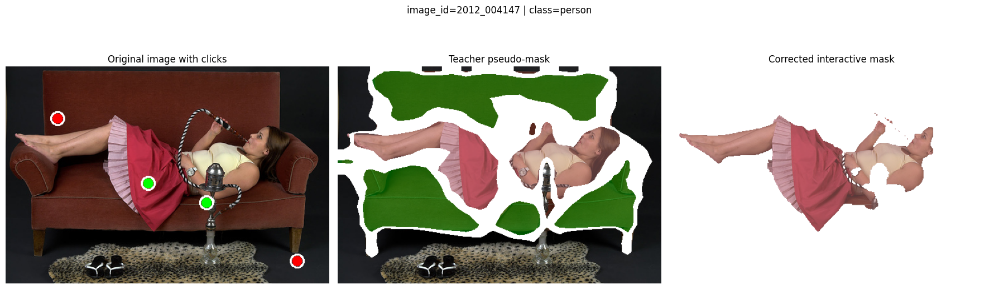

In [117]:
interactive_specs: list[dict] = [
    {
        "image_id": interactive_candidates_df.iloc[0]["image_id"] if len(interactive_candidates_df) else None,
        "target_class_id": 15,
        "positive_clicks": [(220, 180), (310, 210)],
        "negative_clicks": [(80, 80), (450, 300)],
    }
] if len(interactive_candidates_df) else []

if interactive_specs:
    spec = interactive_specs[0]
    if spec["image_id"] is None:
        raise ValueError("interactive_specs[0]['image_id'] is None. Select a valid candidate image first.")

    interactive_row = interactive_candidates_df.loc[
        interactive_candidates_df["image_id"] == spec["image_id"]
    ].iloc[0]

    interactive_image = np.array(Image.open(interactive_row["image_path"]).convert("RGB"))
    interactive_pseudo_mask = np.array(Image.open(interactive_row["pseudo_path"]))

    interactive_corrected_mask = refine_mask_with_clicks(
        image=interactive_image,
        pseudo_mask=interactive_pseudo_mask,
        target_class_id=int(spec["target_class_id"]),
        positive_clicks=spec["positive_clicks"],
        negative_clicks=spec["negative_clicks"],
    )

    visualize_interactive_correction(
        image=interactive_image,
        pseudo_mask=interactive_pseudo_mask,
        corrected_mask=interactive_corrected_mask,
        positive_clicks=spec["positive_clicks"],
        negative_clicks=spec["negative_clicks"],
        title=f"image_id={spec['image_id']} | class={VOC_CLASSES.get(int(spec['target_class_id']), spec['target_class_id'])}",
    )
else:
    print("interactive_specs is empty. Fill it with real image IDs and click coordinates, then rerun this cell.")